In [ ]:
# ============================================================
# Preparing Data
# ============================================================

In [1]:
# ============================================================
# Imports
# ============================================================
import os
import re
import random
import pickle
from pathlib import Path
from collections import defaultdict, OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

import mne
from mne.decoding import (SlidingEstimator, LinearModel, get_coef,
                          cross_val_multiscore)

from scipy.stats import ttest_rel, ttest_1samp
from scipy.signal import windows

from statsmodels.formula.api import mixedlm
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf

import pingouin as pg

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV

from pymer4.models import Lmer

from tqdm import tqdm


In [2]:
# Prepare the epochs for analysis

# Define the path to your folder containing the epoch files
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))

# Containers for data
evokeds_list = []
evokeds_list2 = []
evokeds_list3 = []

# Loop over each epoch file
for epoch_file in epoch_files:
    participant_id = epoch_file.stem.split("-epo")[0]
    epochs = mne.read_epochs(epoch_file, preload=True)

    # Create new column for 'target-voice' classification
    epochs.metadata["target-voice"] = epochs.metadata["target"].apply(
        lambda w: "voiced" if w in ["dear", "beach"] else "voiceless")

    # Filter by 'task-relevant' field
    for task_label in ['yes', 'no']:
        task_subset = epochs[epochs.metadata["task-relevant"] == task_label]

        # --- Discrete steps (VOT_step and F0_step) ---
        for vot in task_subset.metadata["VOT_step"].unique():
            for f0 in task_subset.metadata["F0_step"].unique():
                mask = (task_subset.metadata["VOT_step"] == vot) & (task_subset.metadata["F0_step"] == f0)
                vot_f0_subset = task_subset[mask]
                if len(vot_f0_subset) == 0:
                    continue

                evoked = vot_f0_subset.average()
                evoked.comment = f"subj-{participant_id}_task-{task_label}_VOT-{vot}_F0-{f0}"
                evokeds_list.append(evoked)

        # --- Continuous values (VOT and F0) ---
        for vot in task_subset.metadata["VOT"].unique():
            for f0 in task_subset.metadata["F0"].unique():
                mask = (task_subset.metadata["VOT"] == vot) & (task_subset.metadata["F0"] == f0)
                vot_f0_subset = task_subset[mask]
                if len(vot_f0_subset) == 0:
                    continue

                evoked2 = vot_f0_subset.average()
                evoked2.comment = f"subj-{participant_id}_task-{task_label}_VOT-{vot}_F0-{f0}"
                evokeds_list2.append(evoked2)

        # --- Steps from target (VOT and F0) ---
        for vot in task_subset.metadata["vot-stepsfromtarget"].unique():
            for f0 in task_subset.metadata["f0-stepsfromtarget"].unique():
                for voice in task_subset.metadata["target-voice"].unique():
                    mask = (
                        (task_subset.metadata["vot-stepsfromtarget"] == vot) &
                        (task_subset.metadata["f0-stepsfromtarget"] == f0) &
                        (task_subset.metadata["target-voice"] == voice))
                    vot_f0_subset = task_subset[mask]
                    if len(vot_f0_subset) == 0:
                        continue
    
                    evoked3 = vot_f0_subset.average()
                    evoked3.comment = f"subj-{participant_id}_task-{task_label}_VOT-{vot}_F0-{f0}_voice-{voice}"
                    evokeds_list3.append(evoked3)


Reading /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/epochs/111-epo.fif ...


    Found the data of interest:
        t =    -100.10 ...     799.80 ms
        0 CTF compensation matrices available
Adding metadata with 35 columns
1187 matching events found
No baseline correction applied
0 projection items activated
Reading /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/epochs/145-epo.fif ...
    Found the data of interest:
        t =    -100.10 ...     799.80 ms
        0 CTF compensation matrices available
Adding metadata with 35 columns
1036 matching events found
No baseline correction applied
0 projection items activated
Reading /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/epochs/127-epo.fif ...
    Found the data of interest:
        t =    -100.10 ...     799.80 ms
        0 CTF compensation matrices available
Adding metadata with 35 columns
1197 matching events found
No baseline correction applied
0 projection items activated
Reading /Users/chiara/Documents/Projects/NIproject/Full_data/Aco

In [3]:
# === EXCLUSION CRITERIA ===

# === SETTINGS ===
max_bad_channels = 3
max_dropped_epochs_pct = 10  
total_epochs_per_participant = 1200
min_prop_voiced = 0.5
min_accuracy = 0.7

mne.set_log_level('WARNING')

# === PATHS ===
epochs_folder = Path(os.getcwd()) / "epochs/"
log_folder = Path(os.getcwd()) / "logs/"

epoch_files = list(epochs_folder.glob("*-epo.fif"))
log_files = list(log_folder.glob("*.log"))

def clean_id(s):
    return s.replace("subj-", "").strip()

# === BEHAVIOR AND EPOCH COUNTS ===
behavior_summary = []
epochs_summary = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)

    epochs.metadata["target-voice"] = epochs.metadata["target"].apply(
        lambda w: "voiced" if w in ["dear", "beach"] else "voiceless"
    )

    df_yes = epochs.metadata[epochs.metadata["task-relevant"] == "yes"].copy()
    df_yes["oddball_response.keys"] = df_yes["oddball_response.keys"].fillna("incorrect")

    mask_voiced = (df_yes["target-voice"] == "voiced") & (df_yes["VOT"] == 1) & (df_yes["F0"] == 1)
    mask_voiceless = (df_yes["target-voice"] == "voiceless") & (df_yes["VOT"] == 5) & (df_yes["F0"] == 5)

    prop_voiced = (df_yes[mask_voiced]["oddball_response.keys"] == "n").mean() if mask_voiced.sum() > 0 else 0
    prop_voiceless = (df_yes[mask_voiceless]["oddball_response.keys"] == "n").mean() if mask_voiceless.sum() > 0 else 0

    mean_accuracy = round((prop_voiced + prop_voiceless) / 2, 2)

    behavior_summary.append({
        "participant": participant_id,
        "prop_voiced": prop_voiced,
        "prop_voiceless": prop_voiceless,
        "mean_accuracy": mean_accuracy
    })

    n_epochs = len(epochs)
    dropped_epochs = total_epochs_per_participant - n_epochs
    pct_dropped = (dropped_epochs / total_epochs_per_participant) * 100

    epochs_summary.append({
        "participant": participant_id,
        "n_epochs": n_epochs,
        "pct_dropped_epochs": pct_dropped
    })

behavior_df = pd.DataFrame(behavior_summary)
epochs_df = pd.DataFrame(epochs_summary)

# === BAD CHANNELS FROM LOGS ===
channels_summary = []

for log_file in log_files:
    participant_id = clean_id(log_file.stem)
    final_bad_channels = []

    with open(log_file, "r") as f:
        for line in f:
            if "Bad channels" in line:
                channels = re.findall(r"'(.*?)'|\"(.*?)\"", line)
                channels = [c[0] if c[0] else c[1] for c in channels]
                final_bad_channels = channels

    channels_summary.append({
        "participant": participant_id,
        "n_bad_channels": len(final_bad_channels)
    })

channels_df = pd.DataFrame(channels_summary)

# === MERGE AND APPLY EXCLUSION CRITERIA ===
summary_df = (
    behavior_df
    .merge(channels_df, on="participant", how="outer")
    .merge(epochs_df, on="participant", how="outer")
)

summary_df["exclude"] = (
    (summary_df["n_bad_channels"] > max_bad_channels) |
    (summary_df["prop_voiced"] < min_prop_voiced)
)

excluded = summary_df.loc[summary_df["exclude"], "participant"].tolist()
included = summary_df.loc[~summary_df["exclude"], "participant"].tolist()

# === APPLY TO EVOKEDS ===
evokeds_list_full = evokeds_list.copy()
evokeds_list2_full = evokeds_list2.copy()
evokeds_list3_full = evokeds_list3.copy()

evokeds_list = [
    evk for evk in evokeds_list_full
    if evk.comment.split("_")[0].split("-")[1] not in excluded
]
evokeds_list2 = [
    evk for evk in evokeds_list2_full
    if evk.comment.split("_")[0].split("-")[1] not in excluded
]
evokeds_list3 = [
    evk for evk in evokeds_list3_full
    if evk.comment.split("_")[0].split("-")[1] not in excluded
]

# === OUTPUT ===
print("Participants to exclude:", excluded)
print("Participants to include:", included)
print("Total included:", len(included))
print("Total excluded:", len(excluded))


Participants to exclude: ['108', '109', '114', '115', '117', '119', '121', '133', '138', '144']
Participants to include: ['105', '106', '107', '110', '111', '112', '113', '116', '120', '123', '124', '125', '127', '128', '129', '130', '131', '132', '134', '135', '136', '137', '139', '140', '141', '142', '143', '145', '146', '147']
Total included: 30
Total excluded: 10


In [ ]:
# ============================================================
# Analysis 0: Behavioral data
# ============================================================

/Users/chiara/miniforge3/envs/mne/lib/python3.14/site-packages/rpy2/robjects/pandas2ri.py:65: UserWarning: Error while trying to convert the column "F0". Fall back to string conversion. The error is: Converting pandas "Category" series to R factor is only possible when categories are strings.
  warnings.warn('Error while trying to convert '
/Users/chiara/miniforge3/envs/mne/lib/python3.14/site-packages/rpy2/robjects/pandas2ri.py:65: UserWarning: Error while trying to convert the column "VOT". Fall back to string conversion. The error is: Converting pandas "Category" series to R factor is only possible when categories are strings.
  warnings.warn('Error while trying to convert '
/Users/chiara/miniforge3/envs/mne/lib/python3.14/site-packages/rpy2/robjects/pandas2ri.py:65: UserWarning: Error while trying to convert the column "f0_tgt". Fall back to string conversion. The error is: Converting pandas "Category" series to R factor is only possible when categories are strings.
  warnings.warn

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: resp~vot_tgt_center*f0_tgt_center+(vot_tgt_center*f0_tgt_center||participant)

Family: binomial	 Inference: parametric

Number of observations: 17968	 Groups: {'participant': 30.0}

Log-likelihood: -7757.391 	 AIC: 15530.781

Random effects:

                                       Name    Var    Std
participant                     (Intercept)  0.199  0.446
participant.1                vot_tgt_center  0.221  0.470
participant.2                 f0_tgt_center  0.046  0.215
participant.3  vot_tgt_center:f0_tgt_center  0.012  0.111

No random effect correlations specified

Fixed effects:

Fixed effects:
                               Estimate Std. Error  z value  Pr(>|z|)
(Intercept)                     0.32800    0.08400    3.896   < 2e-16 ***
vot_tgt_center                  1.38400    0.08800   15.692   < 2e-16 ***
f0_tgt_center                   0.51100    0.04700   10.849   < 2e-16 ***
vot_tgt_center:f0_tgt_center   -0.0

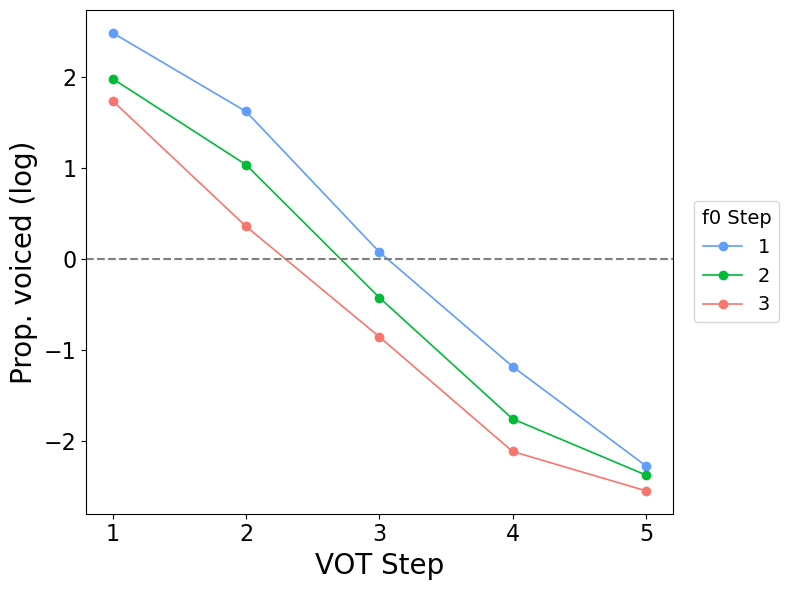

/var/folders/6d/q5zm6vz16rg26bp8fp839p780000gn/T/ipykernel_57056/3187304590.py:172: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: (g["oddball_response.keys"] == "m").mean())


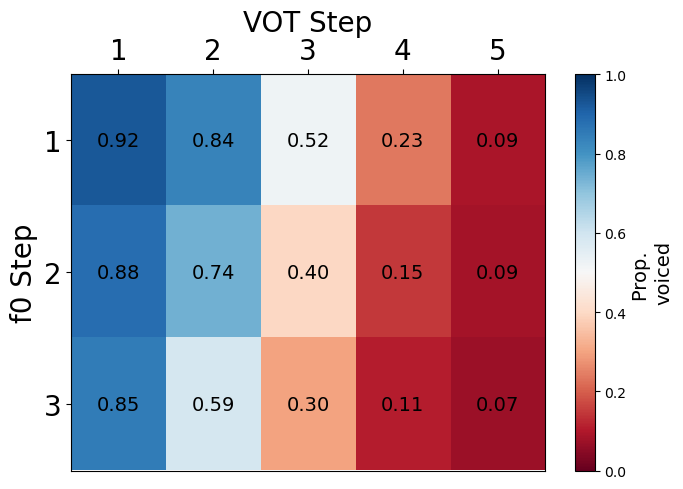

In [4]:
# =========================================================
# Oddball behavioral analysis  (Python port of oddball.R)
# =========================================================

# ---------------------------------------------------------
# Reference data (embedded — replaces Reference.csv/.xlsx)
# Joined to the behavioral data on audio_clip (== "Sound" in R)
# ---------------------------------------------------------
reference = pd.DataFrame({
    "audio_clip": [
        "Stimuli_channel3/bp1_1.wav", "Stimuli_channel3/bp1_3.wav", "Stimuli_channel3/bp1_5.wav",
        "Stimuli_channel3/bp2_1.wav", "Stimuli_channel3/bp2_3.wav", "Stimuli_channel3/bp2_5.wav",
        "Stimuli_channel3/bp3_1.wav", "Stimuli_channel3/bp3_3.wav", "Stimuli_channel3/bp3_5.wav",
        "Stimuli_channel3/bp4_1.wav", "Stimuli_channel3/bp4_3.wav", "Stimuli_channel3/bp4_5.wav",
        "Stimuli_channel3/bp5_1.wav", "Stimuli_channel3/bp5_3.wav", "Stimuli_channel3/bp5_5.wav",
        "Stimuli_channel3/dt1_1.wav", "Stimuli_channel3/dt1_3.wav", "Stimuli_channel3/dt1_5.wav",
        "Stimuli_channel3/dt2_1.wav", "Stimuli_channel3/dt2_3.wav", "Stimuli_channel3/dt2_5.wav",
        "Stimuli_channel3/dt3_1.wav", "Stimuli_channel3/dt3_3.wav", "Stimuli_channel3/dt3_5.wav",
        "Stimuli_channel3/dt4_1.wav", "Stimuli_channel3/dt4_3.wav", "Stimuli_channel3/dt4_5.wav",
        "Stimuli_channel3/dt5_1.wav", "Stimuli_channel3/dt5_3.wav", "Stimuli_channel3/dt5_5.wav",
    ],
    "Continuum": ["beach - peach"] * 15 + ["dear - tear"] * 15,
    "F0":  [1, 3, 5] * 10,
    "VOT": [1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 5] * 2,
})

# ---------------------------------------------------------
# Importing and combining the per-participant CSV files
# ---------------------------------------------------------
behavior_folder = Path(os.getcwd()) / "behavior/"
csv_files = sorted(behavior_folder.glob("*_ob.csv"))

data = pd.concat(
    [pd.read_csv(f, dtype={"participant": str}) for f in csv_files],
    ignore_index=True,
)

# Add reference data (left join, R: by = c("audio_clip" = "Sound"))
data = data.merge(reference, on="audio_clip", how="left")

# Derive targetVoice
data["targetVoice"] = np.where(
    data["target"].isin(["dear", "beach"]), "voiced", "voiceless"
)

# Mark whether the target belongs to the presented continuum
data["relevant"] = data.apply(
    lambda r: "relevant"
    if isinstance(r["Continuum"], str) and r["target"] in r["Continuum"].split(" - ")
    else "notRelevant",
    axis=1,
)

# Exclude participants (behavioral exclusions from oddball.R;
# kept separate from the EEG `excluded`/`included` lists defined above)
behavior_excluded = [101, 102, 103, 104, 118, 122, 126, 108, 109,
                     114, 115, 117, 119, 121, 133, 138, 144]
data = data[~data["participant"].isin([str(p) for p in behavior_excluded])]

# ---------------------------------------------------------
# Relabel so that higher = more target-like
# ---------------------------------------------------------
data["vot_tgt"] = np.where(data["targetVoice"] == "voiced", 6 - data["VOT"], data["VOT"])
data["f0_tgt"]  = np.where(data["targetVoice"] == "voiced", 6 - data["F0"],  data["F0"])

# Compress F0 levels: 1 -> 1, 3 -> 2, 5 -> 3
f0_recode = {1: 1, 3: 2, 5: 3}
data["F0"]     = data["F0"].map(f0_recode).astype("category")
data["VOT"]    = data["VOT"].astype("category")
data["f0_tgt"] = data["f0_tgt"].map(f0_recode).astype("category")

# Keep only valid keypress responses
data = data[data["oddball_response.keys"].isin(["m", "n"])]

data_full = data.copy()
data = data[data["relevant"] == "relevant"]

# ---------------------------------------------------------
# Center predictors
# ---------------------------------------------------------
data["vot_tgt_center"] = data["vot_tgt"].astype(float) - data["vot_tgt"].astype(float).mean()
data["f0_tgt_center"]  = data["f0_tgt"].astype(float) - data["f0_tgt"].astype(float).mean()

data["participant"] = data["participant"].astype("category")

# ---------------------------------------------------------
# Logistic regression (GLMM)
# R modeled as.factor(keys) (alphabetical -> reference "m", models P("n"))
# ---------------------------------------------------------
data["resp"] = (data["oddball_response.keys"] == "n").astype(int)

glm_stops = Lmer(
    "resp ~ vot_tgt_center * f0_tgt_center + (vot_tgt_center * f0_tgt_center || participant)",
    data=data,
    family="binomial",
)
res = glm_stops.fit()


# ---- Print fixed effects in R summary() style ----
def _sig_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    if p < 0.1:   return "."
    return ""

def _fmt_p(p):
    if p < 2e-16: return "< 2e-16"
    if p < 1e-4:  return f"{p:.2e}"
    return f"{p:.3g}"

def print_fixef(res):
    # pymer4 column names for a binomial GLMM
    est = res["Estimate"]
    se  = res["SE"]
    z   = res["Z-stat"]
    p   = res["P-val"]

    name_w = max(len(str(i)) for i in res.index)
    print("Fixed effects:")
    header = (f"{'':<{name_w}} {'Estimate':>10} {'Std. Error':>10} "
              f"{'z value':>8} {'Pr(>|z|)':>9}")
    print(header)
    for term in res.index:
        stars = _sig_stars(p[term])
        print(f"{term:<{name_w}} {est[term]:>10.5f} {se[term]:>10.5f} "
              f"{z[term]:>8.3f} {_fmt_p(p[term]):>9} {stars}")
    print("---")
    print("Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1")

print_fixef(res)

# ---------------------------------------------------------
# Figures
# ---------------------------------------------------------
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

# --- Figure 1: categorization function (log-odds line plot) ---
data_summary1 = (
    data.groupby(["vot_tgt", "f0_tgt"], observed=True)
    .apply(lambda g: (g["oddball_response.keys"] == "m").mean())
    .reset_index(name="prop_m")
)
data_summary1["log_odds"] = np.log(data_summary1["prop_m"] / (1 - data_summary1["prop_m"]))
data_summary1["f0_tgt"]   = data_summary1["f0_tgt"].astype(int)
data_summary1["vot_tgt"]  = data_summary1["vot_tgt"].astype(int)

colors = {1: "#619CFF", 2: "#00ba38", 3: "#f8766d"}

fig, ax = plt.subplots(figsize=(8, 6))
for f0_val, g in data_summary1.groupby("f0_tgt"):
    g = g.sort_values("vot_tgt")
    ax.plot(g["vot_tgt"], g["log_odds"], color=colors[f0_val],
            linewidth=1.2, marker="o", markersize=6, label=str(f0_val))
ax.axhline(0, linestyle="--", color="gray")
ax.set_xlabel("VOT Step", fontsize=20)
ax.set_ylabel("Prop. voiced (log)", fontsize=20)
ax.tick_params(axis="both", labelsize=16)
# Legend on the right, outside the plot area
ax.legend(title="f0 Step", fontsize=14, title_fontsize=14,
          loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
fig.savefig(figures_folder / "behavior_categorization.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figure 2: tile plot (prop. voiced) ---
data_summary2 = (
    data.dropna(subset=["vot_tgt", "f0_tgt"])
    .groupby(["vot_tgt", "f0_tgt"], observed=True)
    .apply(lambda g: (g["oddball_response.keys"] == "m").mean())
    .reset_index(name="prop_m")
)
data_summary2["f0_tgt"]  = data_summary2["f0_tgt"].astype(int)
data_summary2["vot_tgt"] = data_summary2["vot_tgt"].astype(int)

pivot = (
    data_summary2.pivot(index="f0_tgt", columns="vot_tgt", values="prop_m")
    .sort_index(ascending=True)  # reversed order: lowest f0 on top
)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=20)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=20)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.set_xlabel("VOT Step", fontsize=20)
ax.set_ylabel("f0 Step", fontsize=20)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=14, color="black")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Prop. \nvoiced", fontsize=14)
plt.tight_layout()
fig.savefig(figures_folder / "behavior_tile.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Analysis 1: Amplitude differences
# ============================================================

Figure saved: /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/figures/VOT_steps_comparison.png


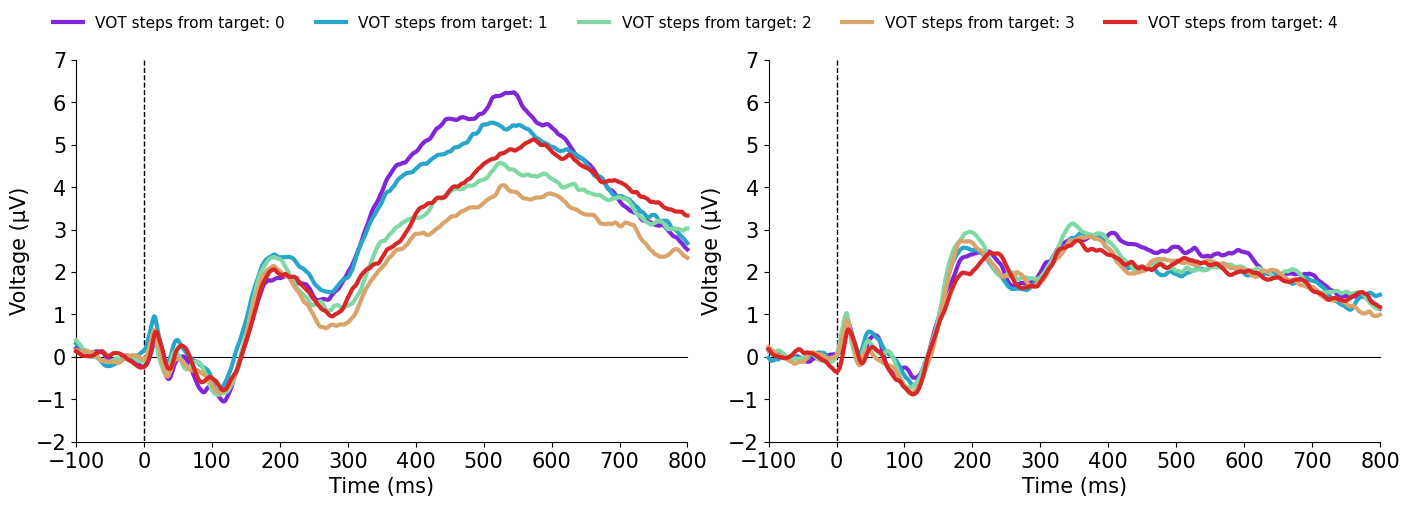

In [5]:
# -------------------------------------------------------
# VOT steps from target
# -------------------------------------------------------

figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

# Extract all task labels
tasks = set()
for evoked in evokeds_list3:
    match = re.search(r'task-([\w]+)', evoked.comment)
    if match:
        tasks.add(match.group(1))

tasks_list = sorted(tasks)

if len(tasks_list) >= 2:
    # yes_VOT on the left, no_VOT on the right
    if 'no_VOT' in tasks_list and 'yes_VOT' in tasks_list:
        tasks_list = ['yes_VOT', 'no_VOT']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    all_legend_lines = None
    colors = None

    for idx, task in enumerate(tasks_list[:2]):
        ax = axes[idx]

        task_subset = [evk for evk in evokeds_list3 if f"task-{task}" in evk.comment]

        # Group by VOT steps from target
        step_groups = defaultdict(list)
        for evk in task_subset:
            match = re.search(r'VOT-([\d]+)', evk.comment)
            if match:
                vot_step = int(match.group(1)) - 1  # Convert from 1–5 to 0–4
                step_groups[f"VOT steps from target: {vot_step}"].append(evk)

        ordered_step_groups = OrderedDict(
            sorted(step_groups.items(), key=lambda x: int(x[0].split()[4]))
        )

        mne.viz.plot_compare_evokeds(
            ordered_step_groups,
            combine='mean',
            picks=['Pz', 'P3', 'P4'],
            title="",
            cmap=None,
            axes=ax,
            ylim=dict(eeg=[-2, 7]),
            legend=False,
            time_unit="ms",
            ci=False,
            show=False
        )

        # Remove any extra axes (e.g. colorbars)
        while len(fig.axes) > 2:
            fig.axes[2].remove()

        ax.set_xlabel("Time (ms)", fontsize=15)
        ax.set_ylabel("Voltage (µV)", fontsize=15)
        ax.tick_params(axis='both', labelsize=15)

        for line in ax.lines:
            line.set_linewidth(3)

        if all_legend_lines is None:
            colors_sat = plt.cm.rainbow(np.linspace(0, 1, len(ordered_step_groups)))
            colors = [(c[0]*0.7+0.15, c[1]*0.7+0.15, c[2]*0.7+0.15, c[3]) for c in colors_sat]
            all_legend_lines = [
                mlines.Line2D([0], [0], color=colors[i], lw=3, label=label)
                for i, label in enumerate(ordered_step_groups.keys())
            ]

        for i, line in enumerate(ax.lines):
            if i < len(colors):
                line.set_color(colors[i])

        if ax.get_legend() is not None:
            ax.get_legend().remove()

    fig.legend(
        handles=all_legend_lines,
        loc='upper center',
        ncol=len(all_legend_lines),
        bbox_to_anchor=(0.5, 1.02),
        frameon=False,
        fontsize=11
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    for ax in axes:
        ax.set_xticks(range(-100, 801, 100))
        ax.spines['bottom'].set_bounds(-100, 800)

    save_path = figures_folder / "VOT_steps_comparison.png"
    fig.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
    print(f"Figure saved: {save_path}")

plt.show()

Figure saved: /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/figures/F0_steps_comparison.png


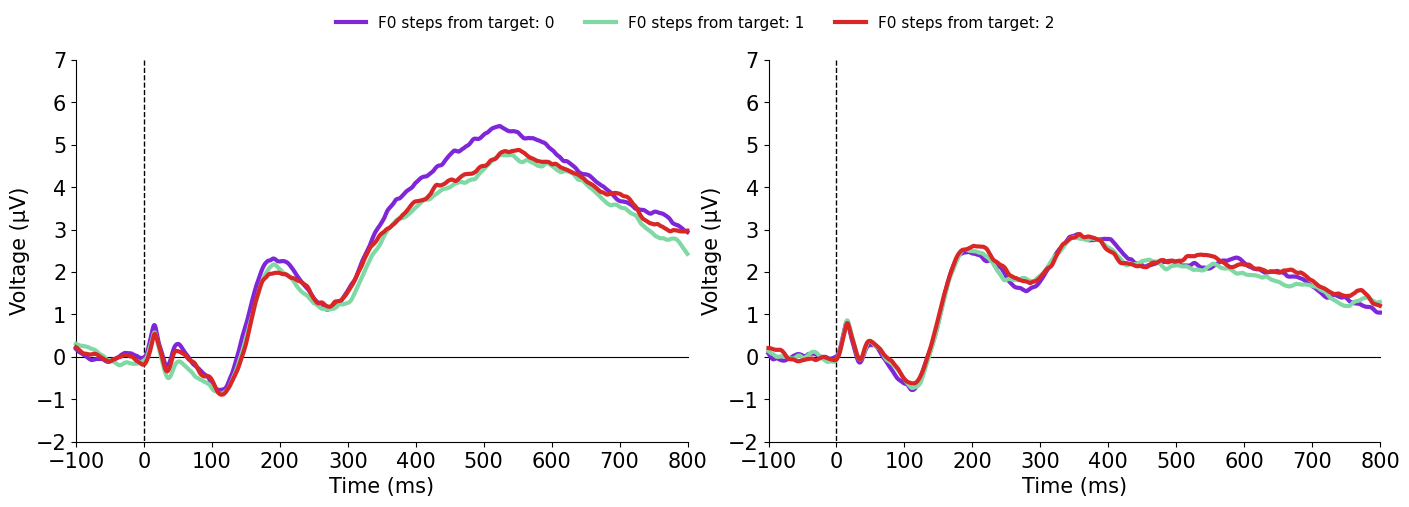

In [6]:
# -------------------------------------------------------
# F0 steps from target
# -------------------------------------------------------

figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

# Extract all task labels
tasks = set()
for evoked in evokeds_list3:
    match = re.search(r'task-([\w]+)', evoked.comment)
    if match:
        tasks.add(match.group(1))

tasks_list = sorted(tasks)

if len(tasks_list) >= 2:
    # yes_VOT on the left, no_VOT on the right
    if 'no_VOT' in tasks_list and 'yes_VOT' in tasks_list:
        tasks_list = ['yes_VOT', 'no_VOT']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    all_legend_lines = None
    colors = None

    for idx, task in enumerate(tasks_list[:2]):
        ax = axes[idx]

        task_subset = [evk for evk in evokeds_list3 if f"task-{task}" in evk.comment]

        # Group by F0 steps from target
        # f0 has 3 levels coded 1/3/5 in the metadata; relabel as 0/1/2
        f0_step_map = {1: 0, 3: 1, 5: 2}
        step_groups = defaultdict(list)
        for evk in task_subset:
            match = re.search(r'F0-([\d]+)', evk.comment)
            if match:
                f0_label = f0_step_map[int(match.group(1))]
                step_groups[f"F0 steps from target: {f0_label}"].append(evk)

        ordered_step_groups = OrderedDict(
            sorted(step_groups.items(), key=lambda x: int(x[0].split()[4]))
        )

        mne.viz.plot_compare_evokeds(
            ordered_step_groups,
            combine='mean',
            picks=['Pz', 'P3', 'P4'],
            title="",
            cmap=None,
            axes=ax,
            ylim=dict(eeg=[-2, 7]),
            legend=False,
            time_unit="ms",
            ci=False,
            show=False
        )

        # Remove any extra axes (e.g. colorbars)
        while len(fig.axes) > 2:
            fig.axes[2].remove()

        ax.set_xlabel("Time (ms)", fontsize=15)
        ax.set_ylabel("Voltage (µV)", fontsize=15)
        ax.tick_params(axis='both', labelsize=15)

        for line in ax.lines:
            line.set_linewidth(3)

        if all_legend_lines is None:
            colors_sat = plt.cm.rainbow(np.linspace(0, 1, len(ordered_step_groups)))
            colors = [(c[0]*0.7+0.15, c[1]*0.7+0.15, c[2]*0.7+0.15, c[3]) for c in colors_sat]
            all_legend_lines = [
                mlines.Line2D([0], [0], color=colors[i], lw=3, label=label)
                for i, label in enumerate(ordered_step_groups.keys())
            ]

        for i, line in enumerate(ax.lines):
            if i < len(colors):
                line.set_color(colors[i])

        if ax.get_legend() is not None:
            ax.get_legend().remove()

    fig.legend(
        handles=all_legend_lines,
        loc='upper center',
        ncol=len(all_legend_lines),
        bbox_to_anchor=(0.5, 1.02),
        frameon=False,
        fontsize=11
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    for ax in axes:
        ax.set_xticks(range(-100, 801, 100))
        ax.spines['bottom'].set_bounds(-100, 800)
        ax.set_xlim(-100, 800)

    save_path = figures_folder / "F0_steps_comparison.png"
    fig.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
    print(f"Figure saved: {save_path}")

plt.show()

In [7]:
# -------------------------------------------------------
# LMM: prepare trial-level data
# -------------------------------------------------------

tmin, tmax = 0.3, 0.6
picks_parietal = ["Pz", "P3", "P4"]
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))

lmm_data = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])

    if participant_id in excluded:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True)

    if epochs.metadata is None:
        continue

    epochs.metadata["target-voice"] = epochs.metadata["target"].apply(
        lambda w: "voiced" if w in ["dear", "beach"] else "voiceless"
    )

    # Mean P3 amplitude per trial at parietal electrodes (300-600 ms window),
    # computed for all trials; task-relevant vs -irrelevant are split below
    epochs_crop = epochs.copy().pick(picks_parietal).crop(tmin=tmin, tmax=tmax)
    mean_voltage = epochs_crop.get_data().mean(axis=(1, 2))

    df = epochs.metadata.copy()
    df["mean_voltage"] = mean_voltage
    df["participant"] = participant_id

    lmm_data.append(df)

df_lmm = pd.concat(lmm_data, ignore_index=True)

# Convert to categorical
df_lmm["F0_step"]       = df_lmm["F0_step"].astype("category")
df_lmm["VOT_step"]      = df_lmm["VOT_step"].astype("category")
df_lmm["target_voice"]  = df_lmm["target-voice"].astype("category")
df_lmm["Continuum"]     = df_lmm["Continuum"].astype("category")
df_lmm["participant"]   = df_lmm["participant"].astype("category")
df_lmm["task_relevant"] = df_lmm["task-relevant"].astype("category")

df_lmm["mean_voltage"] *= 1e6

df_lmm["vot_stepsfromtarget"] = pd.to_numeric(df_lmm["vot-stepsfromtarget"], errors="coerce")
df_lmm["f0_stepsfromtarget"]  = pd.to_numeric(df_lmm["f0-stepsfromtarget"],  errors="coerce")

# List all included participants
participants_included = df_lmm["participant"].unique().tolist()
print("Participants included in LMM data:", len(participants_included))

# -------------------------------------------------------
# LMM: VOT and F0 steps from target (task-relevant trials)
# -------------------------------------------------------

df_lmm_relevant = df_lmm[df_lmm["task-relevant"] == "yes"]

model_interaction = mixedlm(
    "mean_voltage ~ vot_stepsfromtarget * f0_stepsfromtarget",
    df_lmm_relevant, groups=df_lmm_relevant["participant"],
)
print(model_interaction.fit().summary())


Participants included in LMM data: 30
                      Mixed Linear Model Regression Results
Model:                     MixedLM        Dependent Variable:        mean_voltage
No. Observations:          17300          Method:                    REML        
No. Groups:                30             Scale:                     118.4935    
Min. group size:           488            Log-Likelihood:            -65903.7381 
Max. group size:           600            Converged:                 Yes         
Mean group size:           576.7                                                 
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               5.991    0.583 10.276 0.000  4.849  7.134
vot_stepsfromtarget                    -0.559    0.122 -4.578 0.000 -0.798 -0.320


In [8]:
# -------------------------------------------------------
# LMM: task-irrelevant continua (control model)
# Confirms that the amplitude modulation is specific to
# task-relevant processing (cf. task-relevant model above).
# -------------------------------------------------------

df_lmm_irrelevant = df_lmm[df_lmm["task-relevant"] == "no"]

model_interaction_irrel = mixedlm(
    "mean_voltage ~ vot_stepsfromtarget * f0_stepsfromtarget",
    df_lmm_irrelevant, groups=df_lmm_irrelevant["participant"],
)
print(model_interaction_irrel.fit().summary())


                      Mixed Linear Model Regression Results
Model:                     MixedLM        Dependent Variable:        mean_voltage
No. Observations:          17209          Method:                    REML        
No. Groups:                30             Scale:                     116.7937    
Min. group size:           459            Log-Likelihood:            -65430.1812 
Max. group size:           600            Converged:                 Yes         
Mean group size:           573.6                                                 
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               2.607    0.552  4.722 0.000  1.525  3.689
vot_stepsfromtarget                    -0.081    0.122 -0.667 0.504 -0.320  0.157
f0_stepsfromtarget                    

In [ ]:
# ============================================================
# Analysis 2: Timecourse differences
# ============================================================

In [9]:
# -------------------------------------------------------
# Decoding: setup, model, and helper functions
# -------------------------------------------------------


root_dir = Path(os.getcwd()) / "decoding/"
epochs_dir = Path(os.getcwd()) / "epochs/"
epochs_path_template = str(epochs_dir / '{}-epo.fif')

os.makedirs(root_dir, exist_ok=True)

mdl = LogisticRegressionCV(cv=5, class_weight='balanced', max_iter=10000)
cv = 5
n_jobs = -1

seed = 42
np.random.seed(seed)
random.seed(seed)


def temporal_decoding(X, y, cv, n_jobs=1, mdl=None, scoring='accuracy', verbose=True):
    """
    Perform temporal decoding using a sliding estimator.

    Parameters
    ----------
    X : ndarray, shape (n_samples, n_features, n_times)
    y : ndarray, shape (n_samples,)
    cv : int or cross-validation generator
    n_jobs : int
    mdl : sklearn estimator, optional. Defaults to LogisticRegressionCV(cv=5).
    scoring : str. Defaults to 'accuracy'.
    verbose : bool

    Returns
    -------
    scores : ndarray, shape (n_times,)
    model : SlidingEstimator
    coeffs : ndarray, shape (n_sensors, n_times) or (n_classes, n_sensors, n_times)
    """
    clf = make_pipeline(StandardScaler(), LinearModel(mdl))
    model = SlidingEstimator(clf, n_jobs=n_jobs, scoring=scoring, verbose=verbose)

    scores = np.mean(cross_val_multiscore(model, X, y, cv=cv, n_jobs=n_jobs), axis=0)

    model.fit(X, y)
    coeffs = get_coef(model, 'patterns_', inverse_transform=True)

    if len(model.classes_) > 2:
        coeffs = coeffs.transpose(1, 0, 2)  # (n_classes, n_sensors, n_times)

    return scores, model, coeffs


def oleson_significance(all_scores, times, chance_level=0.5,
                        smoothing_ms=50, bin_ms=10, sfreq=1000,
                        alpha=0.05, alternative='greater'):
    """
    Sarrett & Toscano (2024) / Oleson et al. (2017) inspired group-level test.

    Parameters
    ----------
    all_scores : (n_subjects, n_times) array of decoding accuracy.
    times : (n_times,) time vector in seconds.
    chance_level : numerical chance for the t-test (e.g. 0.5 for 2-class).
    smoothing_ms : width of triangular smoothing window applied per subject.
    bin_ms : step (ms) at which to evaluate t-tests after smoothing.
             Set to None to keep every sample.
    sfreq : sampling frequency of the input (Hz).
    alpha : nominal family-wise alpha.
    alternative : 'greater' (one-tailed above chance) or 'two-sided'.

    Returns
    -------
    out : dict with keys
        times_eval, t_obs, p_obs, rho, n_eff, alpha_corrected, sig_mask, smoothed
    """
    # 1. Triangular smoothing per subject
    win_len = max(int(round(smoothing_ms * sfreq / 1000)), 1)
    win = windows.triang(win_len)
    win = win / win.sum()
    smoothed = np.array([np.convolve(s, win, mode='same') for s in all_scores])

    # 2. Coarsen to bin_ms steps
    if bin_ms is not None:
        step = max(int(round(bin_ms * sfreq / 1000)), 1)
        sel = np.arange(0, smoothed.shape[1], step)
    else:
        sel = np.arange(smoothed.shape[1])
    smoothed_c = smoothed[:, sel]
    times_eval = times[sel]

    # 3. One-sample t-test vs chance at each retained time point
    t_obs, p_obs = ttest_1samp(smoothed_c, popmean=chance_level, axis=0,
                               alternative=alternative)

    # 4. Lag-1 autocorrelation of the t-statistic across time
    rho = float(acf(t_obs, nlags=1, fft=False)[1])
    rho = np.clip(rho, -0.999, 0.999)

    # 5. AR(1)-based effective number of independent tests / corrected alpha
    n_tests = len(t_obs)
    n_eff = max(n_tests * (1.0 - rho) / (1.0 + rho), 1.0)
    alpha_corrected = alpha / n_eff
    # import rpy2.robjects as ro
    # from rpy2.robjects.packages import importr

    # bdots = importr('bdots')
    # alpha_corrected = float(bdots.findModifiedAlpha(
    #     rho=ro.FloatVector([float(rho)]),
    #     df=ro.IntVector([int(all_scores.shape[0] - 1)]),
    #     K=ro.IntVector([int(n_tests)]),
    #     alpha=ro.FloatVector([float(alpha)])
    # )[0])

    # 6. Significance
    sig_mask = p_obs < alpha_corrected

    return dict(
        times_eval=times_eval,
        t_obs=t_obs,
        p_obs=p_obs,
        rho=rho,
        n_eff=n_eff,
        alpha_corrected=alpha_corrected,
        sig_mask=sig_mask,
        smoothed=smoothed,
    )


def contiguous_windows(times_eval, sig_mask):
    """Return list of (start_s, end_s) for each contiguous run of True in sig_mask."""
    windows_out = []
    in_run = False
    start = None
    for i, s in enumerate(sig_mask):
        if s and not in_run:
            in_run = True
            start = times_eval[i]
        elif not s and in_run:
            in_run = False
            windows_out.append((start, times_eval[i - 1]))
    if in_run:
        windows_out.append((start, times_eval[-1]))
    return windows_out


100%|██████████| 30/30 [00:00<00:00, 10889.58it/s]

105 already done. Skipping
106 already done. Skipping
107 already done. Skipping
110 already done. Skipping
111 already done. Skipping
112 already done. Skipping
113 already done. Skipping
116 already done. Skipping
120 already done. Skipping
123 already done. Skipping
124 already done. Skipping
125 already done. Skipping
127 already done. Skipping
128 already done. Skipping
129 already done. Skipping
130 already done. Skipping
131 already done. Skipping
132 already done. Skipping
134 already done. Skipping
135 already done. Skipping
136 already done. Skipping
137 already done. Skipping
139 already done. Skipping
140 already done. Skipping
141 already done. Skipping
142 already done. Skipping
143 already done. Skipping
145 already done. Skipping
146 already done. Skipping
147 already done. Skipping
Lag-1 autocorrelation (rho): 0.241
Effective independent tests: 55.01
Corrected alpha: 0.00091

Significant windows:
  361 – 391 ms
  481 – 481 ms
Figure saved: /Users/chiara/Documents/Proje

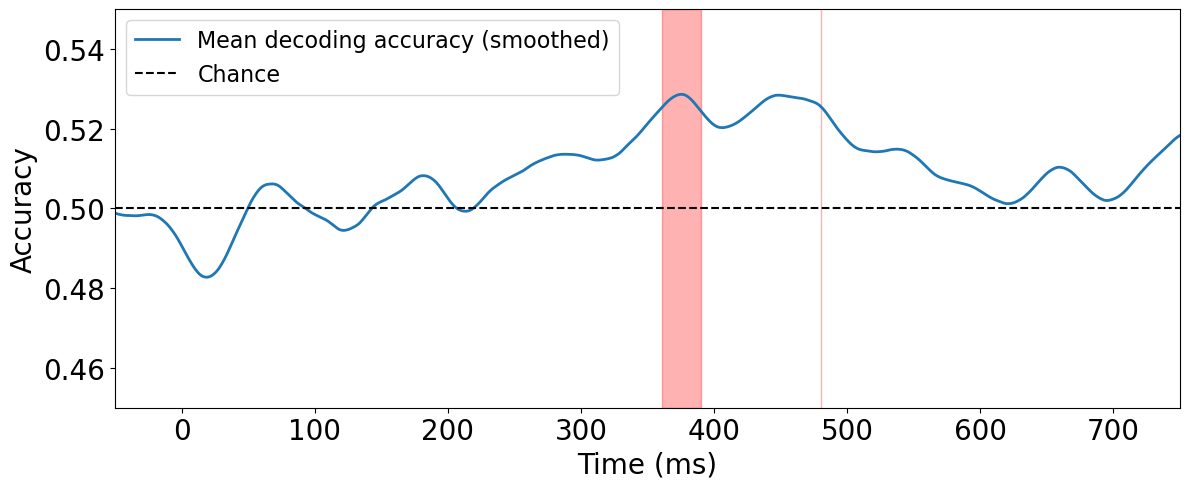

In [10]:
# -------------------------------------------------------
# VOT decoding: steps from target (per participant)
# -------------------------------------------------------

for ptp_id in tqdm(included):
    ptp_results_path = root_dir / f'{ptp_id}_VOTresults.p'

    if os.path.exists(ptp_results_path):
        print(f'{ptp_id} already done. Skipping')
        continue

    print(f'--- {ptp_id} ---')

    epochs = mne.read_epochs(epochs_path_template.format(ptp_id), preload=True, verbose=False)
    epochs.resample(1000, npad="auto")

    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs = epochs[epochs.metadata["vot-stepsfromtarget"].isin([1, 5])]
    epochs = epochs.copy().pick(['Pz', 'P3', 'P4'])

    X = epochs.get_data()
    y = epochs.metadata['vot-stepsfromtarget'].values

    scores, model, coeffs = temporal_decoding(X, y, cv=cv, n_jobs=n_jobs, mdl=mdl, scoring='accuracy', verbose=False)

    with open(ptp_results_path, 'wb') as f:
        pickle.dump({'scores': scores, 'coeffs': coeffs}, f)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(epochs.times, scores)
    ax.axhline(1 / len(np.unique(y)), color='k', linestyle='--', label='chance')
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Participant {ptp_id}: VOT decoding (task-relevant)")
    ax.legend()

    fig.savefig(root_dir / f'{ptp_id}_VOTscores.png', bbox_inches='tight')
    plt.close()


# -------------------------------------------------------
# VOT decoding: group-level statistics (Oleson et al., 2017)
# -------------------------------------------------------

result_files = [
    f for f in sorted(root_dir.glob('*_VOTresults.p'))
    if f.stem.split('_')[0] not in excluded
]

all_scores = []
for res_path in result_files:
    with open(res_path, 'rb') as f:
        subj_res = pickle.load(f)
    if subj_res.get('scores') is not None and len(subj_res['scores']) > 0:
        all_scores.append(subj_res['scores'])

if not all_scores:
    raise ValueError("No valid participant score files found.")

all_scores = np.array(all_scores)  # (n_subjects, n_times)

tmin, tmax = -0.1, 0.8
sfreq = 1000
times = np.linspace(tmin, tmax, all_scores.shape[1])
chance_level = 0.5

res = oleson_significance(
    all_scores, times,
    chance_level=chance_level,
    smoothing_ms=50,
    bin_ms=10,
    sfreq=sfreq,
    alpha=0.05,
    alternative='greater',
)

print(f"Lag-1 autocorrelation (rho): {res['rho']:.3f}")
print(f"Effective independent tests: {res['n_eff']:.2f}")
print(f"Corrected alpha: {res['alpha_corrected']:.5f}")

sig_windows = contiguous_windows(res['times_eval'], res['sig_mask'])
print("\nSignificant windows:")
if not sig_windows:
    print("  none")
for s, e in sig_windows:
    print(f"  {s*1000:.0f} – {e*1000:.0f} ms")

# === Plot ===
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(times * 1000, np.mean(res['smoothed'], axis=0), lw=2, label='Mean decoding accuracy (smoothed)')
ax.axhline(chance_level, linestyle='--', color='k', label='Chance')

for s, e in sig_windows:
    ax.axvspan(s * 1000, e * 1000, color='red', alpha=0.3)

ax.set_xlabel("Time (ms)", fontsize=20)
ax.set_ylabel("Accuracy", fontsize=20)
ax.set_ylim(.450, .550)
ax.set_xlim(-50, 750)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(fontsize=16)

plt.tight_layout()
save_path = figures_folder / "VOT_decoding_oleson.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {save_path}")
plt.show()

100%|██████████| 30/30 [00:00<00:00, 15182.08it/s]

105 already done. Skipping
106 already done. Skipping
107 already done. Skipping
110 already done. Skipping
111 already done. Skipping
112 already done. Skipping
113 already done. Skipping
116 already done. Skipping
120 already done. Skipping
123 already done. Skipping
124 already done. Skipping
125 already done. Skipping
127 already done. Skipping
128 already done. Skipping
129 already done. Skipping
130 already done. Skipping
131 already done. Skipping
132 already done. Skipping
134 already done. Skipping
135 already done. Skipping
136 already done. Skipping
137 already done. Skipping
139 already done. Skipping
140 already done. Skipping
141 already done. Skipping
142 already done. Skipping
143 already done. Skipping
145 already done. Skipping
146 already done. Skipping
147 already done. Skipping
Lag-1 autocorrelation (rho): 0.233
Effective independent tests: 56.03
Corrected alpha: 0.00089

Significant windows:
  401 – 421 ms
Figure saved: /Users/chiara/Documents/Projects/NIproject/F

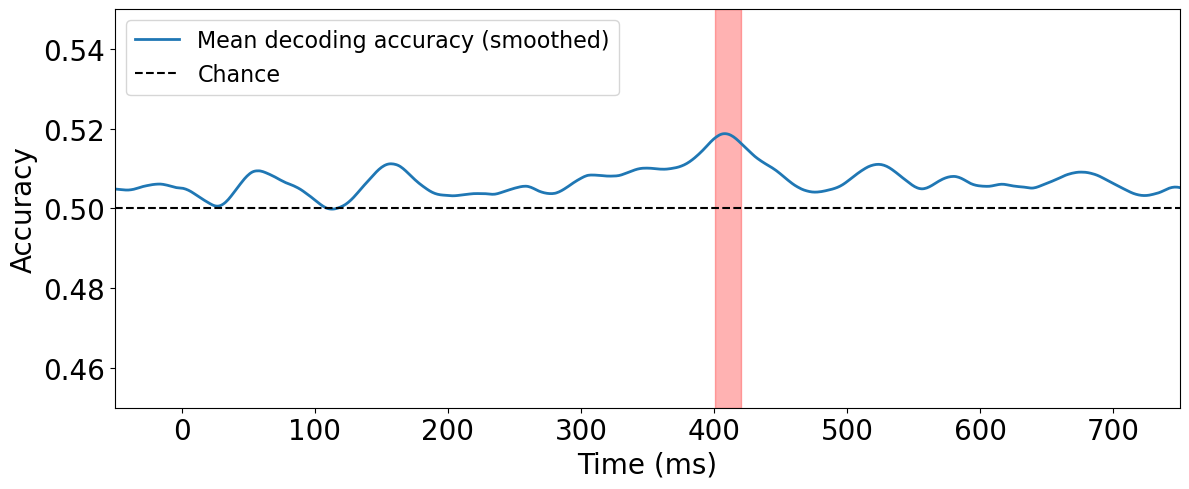

In [11]:
# -------------------------------------------------------
# F0 decoding: steps from target (per participant)
# -------------------------------------------------------

for ptp_id in tqdm(included):
    ptp_results_path = root_dir / f'{ptp_id}_F0results.p'

    if os.path.exists(ptp_results_path):
        print(f'{ptp_id} already done. Skipping')
        continue

    print(f'--- {ptp_id} ---')

    epochs = mne.read_epochs(epochs_path_template.format(ptp_id), preload=True, verbose=False)
    epochs.resample(1000, npad="auto")

    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs = epochs[epochs.metadata["f0-stepsfromtarget"].isin([1, 5])]
    epochs = epochs.copy().pick(['Pz', 'P3', 'P4'])

    X = epochs.get_data()
    y = epochs.metadata['f0-stepsfromtarget'].values

    scores, model, coeffs = temporal_decoding(X, y, cv=cv, n_jobs=n_jobs, mdl=mdl, scoring='accuracy', verbose=False)

    with open(ptp_results_path, 'wb') as f:
        pickle.dump({'scores': scores, 'coeffs': coeffs}, f)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(epochs.times, scores)
    ax.axhline(1 / len(np.unique(y)), color='k', linestyle='--', label='chance')
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Participant {ptp_id}: F0 decoding (task-relevant)")
    ax.legend()

    fig.savefig(root_dir / f'{ptp_id}_F0scores.png', bbox_inches='tight')
    plt.close()


# -------------------------------------------------------
# F0 decoding: group-level statistics (Oleson et al., 2017)
# -------------------------------------------------------

result_files = [
    f for f in sorted(root_dir.glob('*_F0results.p'))
    if f.stem.split('_')[0] not in excluded
]

all_scores = []
for res_path in result_files:
    with open(res_path, 'rb') as f:
        subj_res = pickle.load(f)
    if subj_res.get('scores') is not None and len(subj_res['scores']) > 0:
        all_scores.append(subj_res['scores'])

if not all_scores:
    raise ValueError("No valid participant score files found.")

all_scores = np.array(all_scores)

tmin, tmax = -0.1, 0.8
sfreq = 1000
times = np.linspace(tmin, tmax, all_scores.shape[1])
chance_level = 0.5

res = oleson_significance(
    all_scores, times,
    chance_level=chance_level,
    smoothing_ms=50,
    bin_ms=10,
    sfreq=sfreq,
    alpha=0.05,
    alternative='greater',
)

print(f"Lag-1 autocorrelation (rho): {res['rho']:.3f}")
print(f"Effective independent tests: {res['n_eff']:.2f}")
print(f"Corrected alpha: {res['alpha_corrected']:.5f}")

sig_windows = contiguous_windows(res['times_eval'], res['sig_mask'])
print("\nSignificant windows:")
if not sig_windows:
    print("  none")
for s, e in sig_windows:
    print(f"  {s*1000:.0f} – {e*1000:.0f} ms")

# === Plot ===
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(times * 1000, np.mean(res['smoothed'], axis=0), lw=2, label='Mean decoding accuracy (smoothed)')
ax.axhline(chance_level, linestyle='--', color='k', label='Chance')

for s, e in sig_windows:
    ax.axvspan(s * 1000, e * 1000, color='red', alpha=0.3)

ax.set_xlabel("Time (ms)", fontsize=20)
ax.set_ylabel("Accuracy", fontsize=20)
ax.set_ylim(.450, .550)
ax.set_xlim(-50, 750)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(fontsize=16)

plt.tight_layout()
save_path = figures_folder / "F0_decoding_oleson.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {save_path}")
plt.show()

In [ ]:
# ============================================================
# Analysis 3: Acoustic cue weights
# ============================================================


=== Sphericity (Mauchly) ===
SpherResults(spher=True, W=np.float64(0.8289754855307049), chi2=np.float64(5.1997101673968995), dof=5, pval=np.float64(0.3922568620388153))

=== One-way rm-ANOVA (auto Greenhouse-Geisser if needed) ===
   Source         SS  DF        MS        F   p_unc      np2      eps
condition  43.513528   3 14.504509 8.002639 0.00009 0.216272 0.882586
    Error 157.684523  87  1.812466      NaN     NaN      NaN      NaN

=== Planned one-tailed paired t-tests ===
           Comparison     t   dz p (raw) p (Holm)  Sig (Holm)
Optimal vs Strong VOT 1.429 0.26  0.0818   0.0818       False
 Optimal vs Strong F0 2.607 0.48  0.0071   0.0214        True
Strong VOT vs Neither 3.195 0.58  0.0017   0.0067        True
 Strong F0 vs Neither 2.280 0.42  0.0151   0.0302        True

Figure saved: /Users/chiara/Documents/Projects/NIproject/Full_data/AcousticCuesEEG_OpenSource/figures/cue_weights_anova.png


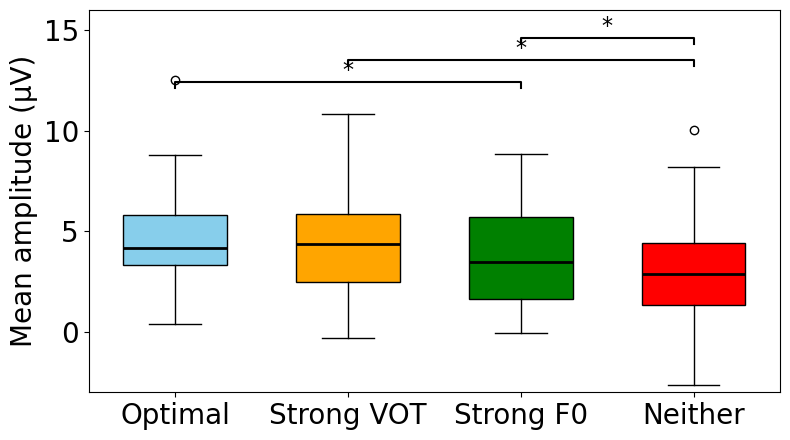

In [12]:
# -------------------------------------------------------
# Cue weights: repeated-measures ANOVA + planned t-tests
# -------------------------------------------------------

picks = ["Pz", "P3", "P4"]
tmin, tmax = 0.3, 0.6
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

conditions = {
    "optimal":    lambda row: ((row["VOT"] == 1) & (row["F0"] == 1)) |
                              ((row["VOT"] == 5) & (row["F0"] == 5)),
    "strong VOT": {"VOT_step": 2, "F0_step": 0},
    "strong F0":  {"VOT_step": 0, "F0_step": 1},
    "neither":    {"VOT_step": 0, "F0_step": 0},
}

data_dict = {cond: [] for cond in conditions}
participants = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    if participant_id not in included:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True)
    epochs.pick(picks)
    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs.crop(tmin=tmin, tmax=tmax)

    participant_data = {}
    skip_participant = False
    for cond_name, cond_vals in conditions.items():
        if callable(cond_vals):
            cond_epochs = epochs[epochs.metadata.apply(cond_vals, axis=1)]
        else:
            cond_epochs = epochs[
                (epochs.metadata["VOT_step"] == cond_vals["VOT_step"]) &
                (epochs.metadata["F0_step"] == cond_vals["F0_step"])
            ]
        if len(cond_epochs) == 0:
            skip_participant = True
            break
        participant_data[cond_name] = cond_epochs.average().data.mean() * 1e6

    if skip_participant:
        print(f"Skipping {participant_id}: missing one or more conditions")
        continue

    for cond_name in conditions:
        data_dict[cond_name].append(participant_data[cond_name])
    participants.append(participant_id)

# === LONG-FORMAT DATAFRAME ===
cond_order = ["optimal", "strong VOT", "strong F0", "neither"]
df_long = pd.DataFrame({
    "participant": np.tile(participants, len(cond_order)),
    "condition":   np.repeat(cond_order, len(participants)),
    "amplitude":   np.concatenate([data_dict[c] for c in cond_order]),
})

# === SPHERICITY CHECK ===
print("\n=== Sphericity (Mauchly) ===")
print(pg.sphericity(df_long, dv="amplitude", within="condition", subject="participant"))

# === ONE-WAY REPEATED-MEASURES ANOVA ===
print("\n=== One-way rm-ANOVA (auto Greenhouse-Geisser if needed) ===")
aov = pg.rm_anova(
    data=df_long,
    dv="amplitude",
    within="condition",
    subject="participant",
    correction="auto",
    detailed=True,
    effsize="np2",
)
print(aov.to_string(index=False))

# === PLANNED ONE-TAILED PAIRED T-TESTS ===
optimal    = np.array(data_dict["optimal"])
strong_vot = np.array(data_dict["strong VOT"])
strong_f0  = np.array(data_dict["strong F0"])
neither    = np.array(data_dict["neither"])

planned_tests = [
    ("Optimal vs Strong VOT", optimal,    strong_vot),
    ("Optimal vs Strong F0",  optimal,    strong_f0),
    ("Strong VOT vs Neither", strong_vot, neither),
    ("Strong F0 vs Neither",  strong_f0,  neither),
]

tvals, raw_pvals = [], []
for _, a, b in planned_tests:
    t, p = ttest_rel(a, b, alternative="greater")
    tvals.append(t)
    raw_pvals.append(p)

reject, p_holm, _, _ = multipletests(raw_pvals, alpha=0.05, method="holm")

def cohens_dz(a, b):
    diff = np.array(a) - np.array(b)
    return diff.mean() / diff.std(ddof=1)

dz_vals = [cohens_dz(a, b) for _, a, b in planned_tests]

results_df = pd.DataFrame({
    "Comparison": [t[0] for t in planned_tests],
    "t":          [f"{v:.3f}" for v in tvals],
    "dz":         [f"{v:.2f}"  for v in dz_vals],
    "p (raw)":    [f"{v:.4f}" for v in raw_pvals],
    "p (Holm)":   [f"{v:.4f}" for v in p_holm],
    "Sig (Holm)": reject,
})
print("\n=== Planned one-tailed paired t-tests ===")
print(results_df.to_string(index=False))

# === PLOT ===
fig, ax = plt.subplots(figsize=(8, 4.5))
x_positions = np.arange(1, len(cond_order) + 1)
colors = ["skyblue", "orange", "green", "red"]

boxplots = ax.boxplot(
    [data_dict[c] for c in cond_order],
    positions=x_positions,
    widths=0.6,
    patch_artist=True,
    boxprops=dict(color="black"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
)
for patch, color in zip(boxplots["boxes"], colors):
    patch.set_facecolor(color)

ax.set_xticks(x_positions)
ax.set_xticklabels(["Optimal", "Strong VOT", "Strong F0", "Neither"], fontsize=20)
ax.set_ylabel("Mean amplitude (µV)", fontsize=20)
ax.tick_params(axis="both", which="major", labelsize=20)
ax.set_ylim(-3, 16)

def add_sig_line(ax, x1, x2, y, h, pval, fontsize=16):
    if pval < 0.05:
        ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], color="black", linewidth=1.5)
        ax.text((x1 + x2) / 2, y + h, "*", ha="center", va="bottom", fontsize=fontsize)

sig_pairs = [
    (1, 2, p_holm[0]),
    (1, 3, p_holm[1]),
    (2, 4, p_holm[2]),
    (3, 4, p_holm[3]),
]

ymax, step = 11, 11 * 0.1
y = ymax
for x1, x2, pval in sig_pairs:
    add_sig_line(ax, x1, x2, y, step * 0.3, pval)
    y += step

plt.tight_layout()
save_path = figures_folder / "cue_weights_anova.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"\nFigure saved: {save_path}")
plt.show()